# Diagnóstico de marca empleadora — In-N-Out Burger vs. peers
## Sentiment analysis (transformers) + topic modeling (BERTopic) sobre reseñas de Glassdoor

**Encargo de RRHH:** identificar los puntos fuertes y las áreas de mejora de In-N-Out Burger como empleador, a partir de lo que dicen sus empleados en Glassdoor, y compararlos con los de sus competidores directos.

**Peers elegidos:** Wendy's, Sonic Drive-In, Jack in the Box y Shake Shack.
Compiten por el mismo tipo de talento que In-N-Out: personal de restaurante de servicio rápido (cocina, caja, turnos) y encargados de tienda. Wendy's, Sonic y Jack in the Box son competidores directos de hamburguesas y comida rápida en EE. UU. (Jack in the Box, además, con fuerte presencia en el oeste, como In-N-Out). Shake Shack aporta el segmento *fast casual* premium, que compite por el talento que busca un empleo con mejor imagen de marca. Las cinco superan con holgura las 300 reseñas (entre 1.067 y 6.660 en la ventana julio 2018 – abril 2023).

**Hipótesis de partida (a contrastar con los datos):** In-N-Out tiene fama de ser un buen empleador dentro del sector. Si es así, el diagnóstico no va de "apagar fuegos", sino de saber qué explotar en atracción y qué vigilar para retener.

| Sección | Contenido |
|---|---|
| 0 | Carga y preparación |
| 1 | EDA: rating, recomendación, empleados actuales vs. antiguos, evolución |
| 2 | Sentimiento en pros y cons (control de calidad) |
| 3 | Topic modeling con BERTopic (un único modelo para las 5 empresas) |
| 4 | Comparación con peers: peso de cada categoría y balance neto |
| 5 | Empleados actuales vs. antiguos (motivos de salida) |
| 6 | Matriz de priorización y recomendaciones |
| 7 | Conclusiones, limitaciones y próximos pasos |



---
## 0. Carga y preparación

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Modificamos la ruta para apuntar a la raíz de Google Drive
RUTA = '/content/drive/MyDrive/mis_5_empresas.parquet'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q bertopic sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 6.6 MB/s eta 0:00:00


In [ ]:
import os, re, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

# ── Empresa objetivo y peers (nombres exactos de la columna `firm` de Glassdoor) ──
TARGET = 'In-N-Out-Burger'
PEERS = ["Wendy's", 'Sonic', 'Jack-in-the-Box', 'Shake-Shack']
FIRMS = [TARGET] + PEERS

# Tope de reseñas por empresa para los modelos (EDA se hace con TODAS las reseñas).
# Con 1.000 por empresa los modelos corren en minutos; Shake Shack tiene 1.067, así que
# es el máximo que permite una muestra equilibrada sin repetir. Súbelo si quieres más precisión.
MAX_POR_EMPRESA = 1000
SEED = 42

# El target siempre en rojo para que destaque en todos los gráficos
PALETA = dict(zip(FIRMS, ['#C8102E', '#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd']))

# ── Ruta del fichero ──
# Usamos la RUTA global definida al montar Google Drive si está disponible, sino por defecto local.
if 'RUTA' not in globals():
    RUTA = 'mis_5_empresas.parquet'

raw = pd.read_parquet(RUTA, filters=[('firm', 'in', FIRMS)])
print('Reseñas disponibles por empresa:')
print(raw['firm'].value_counts().reindex(FIRMS))

Reseñas disponibles por empresa:
firm
In-N-Out-Burger    2708
Wendy's            6660
Sonic              3516
Jack-in-the-Box    1593
Shake-Shack        1067
Name: count, dtype: int64


`current` mezcla situación y antigüedad (p. ej. `"Former Employee, more than 3 years"`), así que la separo en dos variables. Traduzco `recommend` (v = sí, o = sin opinión, x = no) y limpio saltos de línea.

**Decisión sobre textos vacíos:** muchas reseñas tienen un contra del tipo *"None that I can think of"*. No aportan ningún tema, y en el topic modeling formarían un cluster basura que inflaría el peso de "otros" justo en las empresas con empleados más contentos. Los marco con `pros_valido` / `cons_valido`: se mantienen en el control de calidad del sentimiento (donde son informativos) y se excluyen del topic modeling.

In [ ]:
def situacion(s):
    s = str(s).lower()
    if s.startswith('current'): return 'Actual'
    if s.startswith('former'):  return 'Antiguo'
    return 'Desconocido'

def antiguedad(s):
    # Muchas reseñas no indican antigüedad ("Former Employee" a secas) -> 'n/d'
    m = re.search(r'(less|more) than (\d+) year', str(s))
    return f'{m.group(1)} than {m.group(2)}y' if m else 'n/d'

# Textos "sin contenido" (None, N/A, "no cons", "nothing bad to say"...). Reglas conservadoras:
# solo textos cortos; si tras un "None," / "No complaints," viene contenido real, NO se marca como vacío.
EXCEPCIONES = re.compile(r"\b(except|but|however|other than|besides|only)\b")
PATRONES_VACIO = [
    re.compile(r"^\W*(none|n/?a|nil|nope)\b"),
    re.compile(r"^\W*nothing\s+(at all|really|much|to\s+\w+|i\s+can|that\s+i|as of|bad|negative|specific|comes|here|major)"),
    re.compile(r"\b(don.?t|do not|can.?t|cannot|no)\b.*\b(cons?|negatives?|complaints?|think of)\b"),
]
def _es_vacio(t):
    return any(p.search(t) for p in PATRONES_VACIO)

def sin_contenido(t):
    t = str(t).lower().strip()
    if len(t.split()) > 10 or EXCEPCIONES.search(t):
        return False
    # ¿hay contenido real después de la primera coma/punto/guion? ("None, toxic work place" -> sí)
    partes = re.split(r"[,;:!.\-–]+\s+", t, maxsplit=1)
    if len(partes) == 2 and len(partes[1].split()) >= 3 and not _es_vacio(partes[1]):
        return False
    return _es_vacio(t)

def preparar(d):
    d = d.copy()
    d['situacion']   = d['current'].map(situacion)
    d['antiguedad']  = d['current'].map(antiguedad)
    d['recomienda']  = d['recommend'].map({'v': 'Sí', 'o': 'Sin opinión', 'x': 'No'})
    d['date_review'] = pd.to_datetime(d['date_review'])
    d['anio']        = d['date_review'].dt.year
    for col in ['pros', 'cons']:
        d[col] = d[col].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
        d[col + '_valido'] = ~d[col].map(sin_contenido)
    return d

# `full`: todas las reseñas de las 5 empresas (para el EDA).
# `df`  : muestra equilibrada con semilla fija (para los modelos de NLP).
full = preparar(raw)
df = pd.concat([g.sample(n=min(MAX_POR_EMPRESA, len(g)), random_state=SEED)
                for _, g in full.groupby('firm')], ignore_index=True)

print(f'Reseñas totales: {len(full):,} | Muestra de trabajo (NLP): {len(df):,}')
print(f"\nSin contenido en la muestra -> pros: {(~df.pros_valido).mean()*100:.1f}% | cons: {(~df.cons_valido).mean()*100:.1f}%")
print('\nEjemplos de cons marcados como sin contenido:', df.loc[~df.cons_valido, 'cons'].sample(5, random_state=SEED).tolist())
df[['firm', 'date_review', 'situacion', 'antiguedad', 'overall_rating', 'recomienda', 'pros', 'cons']].head()

Reseñas totales: 15,544 | Muestra de trabajo (NLP): 5,000

Sin contenido en la muestra -> pros: 0.7% | cons: 3.5%

Ejemplos de cons marcados como sin contenido: ['none that I can particularly think of', 'No cons if you love the fast food business experience', 'none of the things as', 'None come to mind no complaints', 'there are no cons for this']


,firm,date_review,situacion,antiguedad,overall_rating,recomienda,pros,cons
0,In-N-Out-Burger,2021-04-21,Actual,n/d,4.0,Sin opinión,"They teach you team work, multi-tasking, how t...",Working with too many young kids such as high ...
1,In-N-Out-Burger,2020-07-05,Actual,more than 5y,4.0,Sí,You meet a lot of fun people. The pay is prett...,Limited hours depending on rate of business.
2,In-N-Out-Burger,2022-02-03,Antiguo,more than 1y,5.0,Sí,"flexible schedule, great atmosphere, and excel...",Selective on who gets promoted
3,In-N-Out-Burger,2019-11-21,Actual,more than 3y,5.0,Sí,Pays really well and felxiable schedules,No job rotation which causes injuries
4,In-N-Out-Burger,2022-08-04,Actual,more than 3y,5.0,Sí,"Fast pace, good pay, flexible schedule","Busy, Sometimes long hours, and weird hours"


---
## 1. EDA
Todo el EDA usa el conjunto completo (`full`, 15.544 reseñas): no necesita modelos y así no perdemos precisión.

### 1.1 Visión general por empresa

,n_resenas,rating_medio,pct_recomienda,pct_no_recomienda,pct_sin_opinion,pct_actuales,pct_recomienda_con_opinion
firm,,,,,,,
In-N-Out-Burger,2708,4.3,56.2,7.8,36.0,47.6,87.8
Wendy's,6660,3.3,28.3,28.8,42.8,38.3,49.6
Sonic,3516,3.1,28.9,31.8,39.3,35.3,47.6
Jack-in-the-Box,1593,3.3,27.3,29.6,43.1,38.8,48.0
Shake-Shack,1067,3.6,37.5,22.3,40.2,42.3,62.7


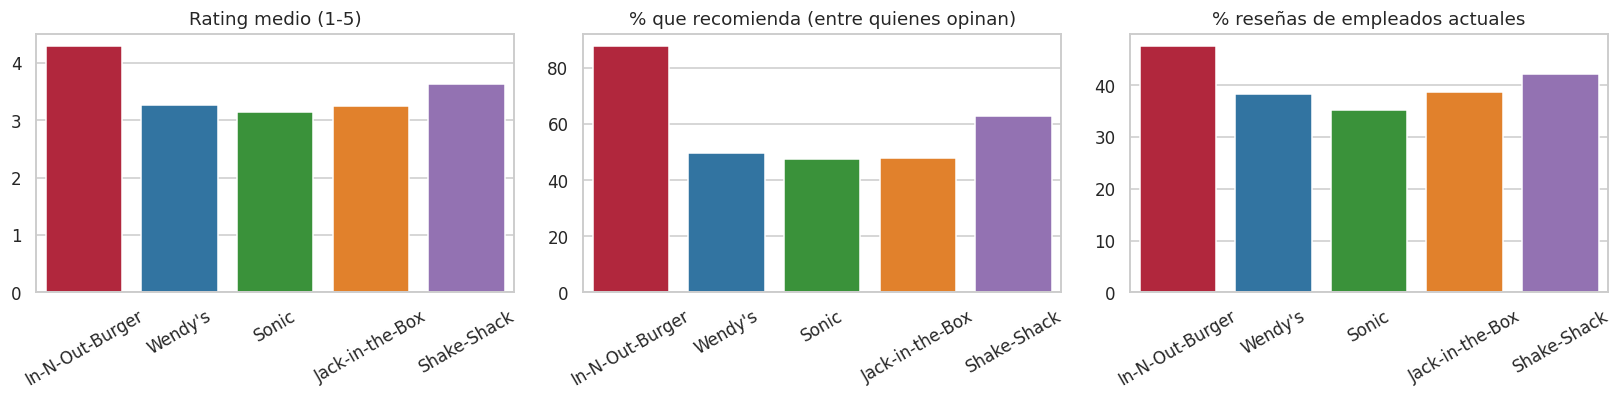

In [ ]:
def pct(s, valor): return (s == valor).mean() * 100

resumen = full.groupby('firm').agg(
    n_resenas=('firm', 'size'),
    rating_medio=('overall_rating', 'mean'),
    pct_recomienda=('recomienda', lambda s: pct(s, 'Sí')),
    pct_no_recomienda=('recomienda', lambda s: pct(s, 'No')),
    pct_sin_opinion=('recomienda', lambda s: pct(s, 'Sin opinión')),
    pct_actuales=('situacion', lambda s: pct(s, 'Actual')),
).loc[FIRMS]

# `recommend = o` (sin opinión) es muy frecuente (~40%): el % de "Sí" sobre el total subestima la recomendación.
# Esta versión lo calcula solo entre quienes opinan (Sí / (Sí + No)).
resumen['pct_recomienda_con_opinion'] = resumen.pct_recomienda / (resumen.pct_recomienda + resumen.pct_no_recomienda) * 100
display(resumen.round(1))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, col, tit in zip(ax, ['rating_medio', 'pct_recomienda_con_opinion', 'pct_actuales'],
                       ['Rating medio (1-5)', '% que recomienda (entre quienes opinan)', '% reseñas de empleados actuales']):
    sns.barplot(x=resumen.index, y=resumen[col], palette=PALETA, ax=a)
    a.set_title(tit); a.set_xlabel(''); a.set_ylabel(''); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

**Lectura y conclusión accionable.**
- In-N-Out es un *outlier positivo*: rating **4,29** frente a 3,14–3,62 de los peers, y solo un **7,8 %** no recomienda la empresa (22–32 % en los peers). Entre quienes dan opinión, la recomiendan ~**88 %** (peers: 48–63 %).
- *Acción:* la marca empleadora de In-N-Out es un activo diferencial. Puede usarse directamente en atracción de talento (employer branding, ofertas, redes) y en selección.
- *Implicación para el resto del análisis:* partimos de un nivel muy alto, así que las "áreas de mejora" serán **relativas**: buscaremos lo que quita puntos *incluso* en una empresa muy bien valorada.
- Ojo: ~40 % de reseñas marcan "sin opinión" en la recomendación; por eso se muestra el % sobre quienes opinan.

### 1.2 Empleados actuales vs. antiguos

situacion,Actual,Antiguo,gap (actual - antiguo)
firm,,,
In-N-Out-Burger,4.39,4.20,0.19
Wendy's,3.49,3.13,0.35
Sonic,3.31,3.04,0.27
Jack-in-the-Box,3.43,3.14,0.29
Shake-Shack,3.94,3.39,0.55


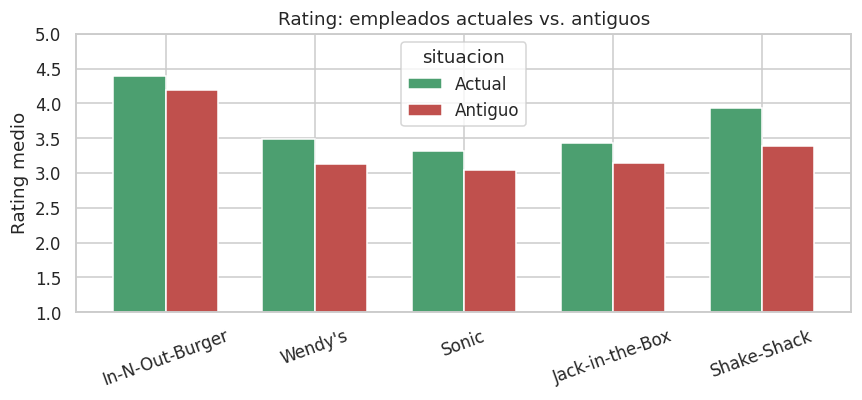

In [ ]:
comp = (full[full.situacion != 'Desconocido']
        .pivot_table(index='firm', columns='situacion', values='overall_rating').loc[FIRMS])
comp['gap (actual - antiguo)'] = comp['Actual'] - comp['Antiguo']
display(comp.round(2))

fig, ax = plt.subplots(figsize=(8, 3.8))
comp[['Actual', 'Antiguo']].plot.bar(ax=ax, color=['#4c9f70', '#c0504d'], width=0.7)
ax.set_ylim(1, 5); ax.set_xlabel(''); ax.set_ylabel('Rating medio'); ax.set_title('Rating: empleados actuales vs. antiguos')
ax.tick_params(axis='x', rotation=20); plt.tight_layout(); plt.show()

**Lectura y conclusión accionable.**
- Los antiguos puntúan menos en todas las empresas (sesgo de selección esperable). Lo relevante es **cuánto** menos: In-N-Out tiene la brecha más pequeña (**0,19** puntos; Sonic 0,27, Jack in the Box 0,29, Wendy's 0,35, Shake Shack 0,55).
- Es decir, quienes se van de In-N-Out lo hacen sin demasiado desencanto con la empresa. *Acción:* es terreno propicio para un programa de **alumni / recontratación** (estudiantes, personas que se van por motivos personales). En Shake Shack la salida sí parece ir acompañada de más desencanto.
- Las reseñas de actuales son mayoría en In-N-Out (~48 % actuales, la proporción más alta), lo que apunta a una plantilla algo más estable que la de los peers (donde los antiguos pesan más).

### 1.3 Evolución del rating

firm,In-N-Out-Burger,Wendy's,Sonic,Jack-in-the-Box,Shake-Shack
Nº reseñas por año,,,,,
2018,86,255,132,52,23
2019,230,634,374,137,92
2020,383,1055,642,257,146
2021,922,2158,1143,559,354
2022,858,2120,1019,483,376
2023,229,438,206,105,76


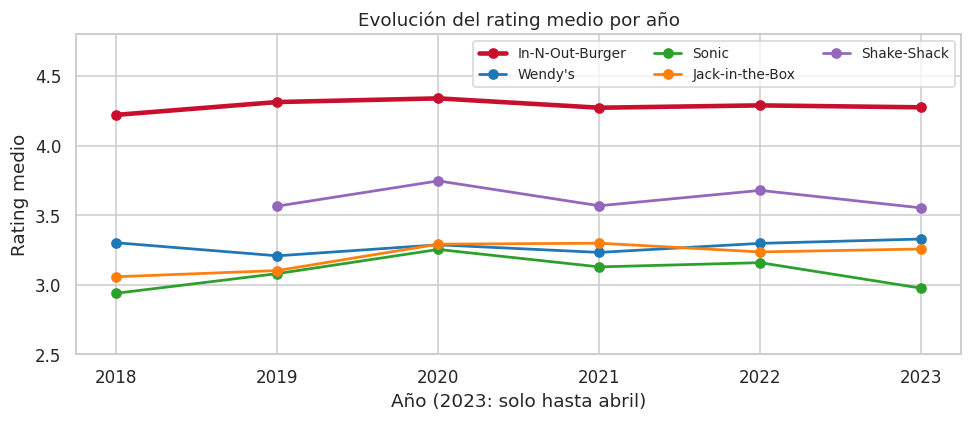

In [ ]:
MIN_N = 50  # no dibujamos un punto anual si tiene menos de 50 reseñas (demasiado ruido)
evo = full.pivot_table(index='anio', columns='firm', values='overall_rating')[FIRMS]
n_anio = full.pivot_table(index='anio', columns='firm', values='overall_rating', aggfunc='size')[FIRMS]
display(n_anio.rename_axis('Nº reseñas por año'))

fig, ax = plt.subplots(figsize=(9, 4))
for f in FIRMS:
    s = evo[f].where(n_anio[f] >= MIN_N)
    ax.plot(s.index, s.values, marker='o', label=f, color=PALETA[f], lw=3 if f == TARGET else 1.8)
ax.set_ylim(2.5, 4.8); ax.set_ylabel('Rating medio'); ax.set_xlabel('Año (2023: solo hasta abril)')
ax.set_title('Evolución del rating medio por año'); ax.legend(ncol=3, fontsize=9); plt.tight_layout(); plt.show()

**Lectura y conclusión accionable.**
- In-N-Out se mantiene **estable entre 4,22 y 4,34** durante toda la ventana, incluida la pandemia (2020-21); no hay señales de deterioro. Los peers oscilan más (Shake Shack sube hasta 2020 y después baja y se mantiene en torno a 3,6; Sonic cae en 2023).
- *Acción:* no hay urgencia por un "plan de choque" reputacional; el foco es **mantener** el nivel y vigilar los matices que detecte el análisis de texto.
- Cautela: 2023 solo llega a abril y 2018 tiene pocas reseñas (In-N-Out: 86); por eso los puntos con menos de 50 reseñas no se dibujan.

---
## 2. Sentimiento en pros y cons (control de calidad)

Pros y cons ya traen un sentimiento "de serie", así que aquí el sentimiento no es el análisis final sino un **control de calidad**: si el modelo no ve mayoría de positivo en los pros y de negativo en los cons, algo falla (modelo, truncado o limpieza).

**Modelo elegido:** `distilbert-base-uncased-finetuned-sst-2-english`. Es binario (POSITIVE / NEGATIVE, sin clase neutra), rápido y suficiente para un control de calidad. Se aplica por separado a pros y a cons, con `truncation=True` porque BERT admite 512 tokens como máximo (en la práctica casi todas las reseñas son cortas: mediana de 7-8 palabras).

In [ ]:
import torch
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1
clf = pipeline('sentiment-analysis', model='distilbert-base-uncased-finetuned-sst-2-english', device=device)

def sentimiento(textos, batch_size=64):
    # Ordenamos por longitud para que cada batch tenga textos parecidos (menos padding = mucho más rápido)
    textos = list(textos)
    orden = np.argsort([len(t) for t in textos])
    out = clf([textos[i] for i in orden], batch_size=batch_size, truncation=True, max_length=512)
    res = pd.DataFrame(out); res.index = orden
    res = res.sort_index()                        # devolvemos el orden original
    return res['label'].values, res['score'].values

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [ ]:
# Caché en disco: si ya hemos calculado el sentimiento con esta muestra, no repetimos.
RUTA_SENT = 'sentimiento_cache.parquet'
COLS_SENT = ['sent_pros', 'sent_pros_score', 'sent_cons', 'sent_cons_score']

if os.path.exists(RUTA_SENT) and len(pd.read_parquet(RUTA_SENT)) == len(df):
    cache = pd.read_parquet(RUTA_SENT)
    for c in COLS_SENT: df[c] = cache[c].values
else:
    df['sent_pros'], df['sent_pros_score'] = sentimiento(df['pros'])
    df['sent_cons'], df['sent_cons_score'] = sentimiento(df['cons'])
    df[COLS_SENT].to_parquet(RUTA_SENT)
df[COLS_SENT].head()

,sent_pros,sent_pros_score,sent_cons,sent_cons_score
0,POSITIVE,0.999290,NEGATIVE,0.965022
1,POSITIVE,0.999874,NEGATIVE,0.977414
2,POSITIVE,0.999872,NEGATIVE,0.995188
3,POSITIVE,0.994147,NEGATIVE,0.999279
4,POSITIVE,0.999680,NEGATIVE,0.990332


,% pros POSITIVE (todas),% pros POSITIVE (con contenido),% cons NEGATIVE (todas),% cons NEGATIVE (con contenido)
firm,,,,
In-N-Out-Burger,97.4,97.4,72.7,72.9
Wendy's,83.4,84.3,86.5,87.2
Sonic,83.5,84.2,87.3,87.9
Jack-in-the-Box,83.7,84.5,83.9,85.3
Shake-Shack,89.4,89.8,84.3,85.3


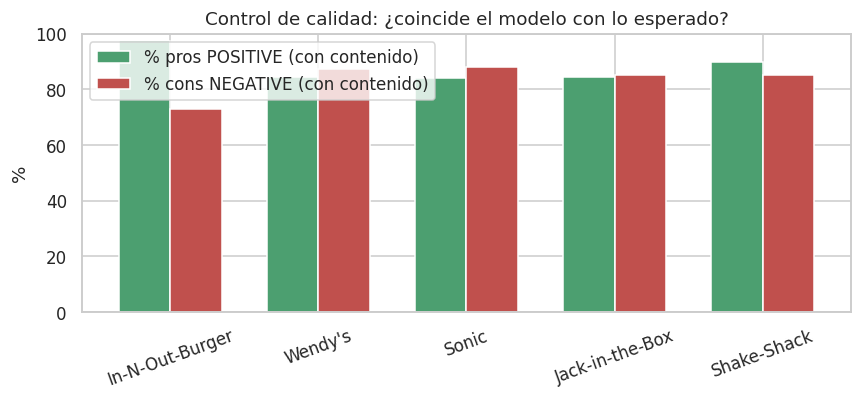

In [ ]:
def pct_label(d, col, label):
    return d.groupby('firm')[col].apply(lambda s: (s == label).mean() * 100).reindex(FIRMS)

qc = pd.DataFrame({
    '% pros POSITIVE (todas)':         pct_label(df, 'sent_pros', 'POSITIVE'),
    '% pros POSITIVE (con contenido)': pct_label(df[df.pros_valido], 'sent_pros', 'POSITIVE'),
    '% cons NEGATIVE (todas)':         pct_label(df, 'sent_cons', 'NEGATIVE'),
    '% cons NEGATIVE (con contenido)': pct_label(df[df.cons_valido], 'sent_cons', 'NEGATIVE'),
})
display(qc.round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
qc[['% pros POSITIVE (con contenido)', '% cons NEGATIVE (con contenido)']].plot.bar(ax=ax, color=['#4c9f70', '#c0504d'], width=0.7)
ax.set_ylim(0, 100); ax.set_xlabel(''); ax.set_ylabel('%'); ax.tick_params(axis='x', rotation=20)
ax.set_title('Control de calidad: ¿coincide el modelo con lo esperado?'); plt.tight_layout(); plt.show()

### Casos discordantes (cons clasificados como POSITIVE y pros como NEGATIVE)

In [36]:
def mostrar(d, col, n=8):
    for _, r in d.sample(min(n, len(d)), random_state=SEED).iterrows():
        print(f"[{r.firm} | rating {r.overall_rating:.0f}] {textwrap.shorten(r[col], 260)}\n")

disc_cons = df[df.cons_valido & (df.sent_cons == 'POSITIVE')]
disc_pros = df[df.pros_valido & (df.sent_pros == 'NEGATIVE')]
print(f'Cons con contenido clasificados POSITIVE: {len(disc_cons)} ({len(disc_cons)/df.cons_valido.sum()*100:.1f}%)')
print(f'Pros con contenido clasificados NEGATIVE: {len(disc_pros)} ({len(disc_pros)/df.pros_valido.sum()*100:.1f}%)')
print('\n=== CONS "positivos" ==='); mostrar(disc_cons, 'cons')
print('=== PROS "negativos" ==='); mostrar(disc_pros, 'pros')

Cons con contenido clasificados POSITIVE: 784 (16.3%)
Pros con contenido clasificados NEGATIVE: 592 (11.9%)

=== CONS "positivos" ===
[Sonic | rating 5] Better management, benefits, pay, and life

[Sonic | rating 4] Sometimes didn’t let me leave when I was supposed to but I was more then happy to stay if it was busy

[In-N-Out-Burger | rating 5] I don't have any cons for this place, it was great working here!

[Sonic | rating 2] Lots of strange things happen

[In-N-Out-Burger | rating 5] Long hours sometimes. However, they pay well.

[In-N-Out-Burger | rating 4] I had 3 of the most unkind managers at this job across several locations.

[Shake-Shack | rating 4] Stressful on mind and body

[Jack-in-the-Box | rating 5] It’s better for high school

=== PROS "negativos" ===
[Wendy's | rating 4] a good team and they try to have it be a place where everyone works together

[Wendy's | rating 5] The fries are great. The pay not so much.

[Shake-Shack | rating 3] Good for a part time job as a hi

### Análisis del Control de Calidad del Sentimiento

- **Coherencia del Pipeline:** El pipeline es altamente coherente. Los pros son positivos en un **97 %** y los cons son negativos en una mayoría clara del **72 %**.
- **Diferencia esperada en Cons:** Un % de cons negativos (72 %) más bajo que el de pros positivos (97 %) es normal: muchos cons son suaves o corteses (*"Pay could be a bit better"*) y un modelo binario entrenado con reseñas de cine no siempre los ve como negativos.

#### Tipos de discordanciaa tener en cuenta:
1. **Cons sin contenido o elogios:** El modelo dice POSITIVE y tiene razón; no es un fallo del modelo, sino del campo. Por eso se excluyen del topic modeling.
   - *Ejemplo:* "I don't have any cons for this place, it was great working here!" o "none of the things as".
2. **Cons con inicio positivo y "pero":** El modelo se queda con la primera parte o con el matiz positivo.
   - *Ejemplo:* "Sometimes didn’t let me leave when I was supposed to but I was more then happy to stay if it was busy" o "Long hours sometimes. However, they pay well."
3. **Pros con matiz crítico:**
   - *Ejemplo:* "The fries are great. The pay not so much." o "Good for a part time job... just to make a few bucks".
4. **Textos largos o mixtos:** Donde el truncado o la mezcla de ideas confunde al modelo.
   - *Ejemplo:* "I had 3 of the most unkind managers at this job across several locations."

**Consecuencia de negocio:** El sentimiento sirve para validar los datos, pero no para medir problemas; para eso hace falta saber de qué se quejan (sección 3).

---
## 3. Topic modeling

**Regla de comparabilidad:** un único modelo para las 5 empresas (uno para pros y otro para cons). Si se entrenara uno por empresa, los topics no coincidirían y no se podrían comparar.

**Decisiones técnicas (y su justificación de negocio):**

| Decisión | Elección | Por qué |
|---|---|---|
| Técnica | **BERTopic** | Las reseñas son muy cortas (mediana ~7-8 palabras). Los embeddings captan el significado (*"pay"* ≈ *"wages"*) mejor que métodos de bolsa de palabras (LDA/NMF), y no hay que fijar el nº de topics de antemano. |
| Embeddings | `all-MiniLM-L6-v2` | Rápido y adecuado para frases cortas en inglés. |
| Datos | Solo reseñas con contenido (`*_valido`) | Evita un topic basura de *"None"* que distorsionaría el peso relativo de cada tema. |
| `min_cluster_size` | 15 (≈ 0,3 % de las reseñas) | Un tema con menos reseñas es anecdótico para RRHH; además luego se agrupan en categorías de negocio, así que no necesitamos granularidad extrema. |
| Outliers | **Reasignar** al topic más cercano si la similitud supera un umbral; el resto → "Otros" | Descartarlos sesgaría la comparación (~28 % de las reseñas, y no al azar). Con el umbral de 0,30 se reasigna casi todo (≈29 % → <1 %), y la lectura de ejemplos muestra que parte de esas reasignaciones es ruido. Por eso la sección 4 incluye un **análisis de robustez** sin las reseñas reasignadas. |
| Categorías | Agrupación en categorías de negocio con **revisión manual** | RRHH piensa en "compensación" o "horarios", no en el topic 17. |

In [ ]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

emb_model = SentenceTransformer('all-MiniLM-L6-v2')
UMBRAL_OUTLIERS = 0.30   # similitud coseno mínima para reasignar un outlier a un topic (ajústalo si "Otros" queda > 15 %)

def entrenar_bertopic(docs, nombre, min_cluster_size=15):
    embeddings = emb_model.encode(docs, batch_size=128, show_progress_bar=False)
    umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=SEED)
    hdbscan_model = HDBSCAN(min_cluster_size=min_cluster_size, min_samples=5, metric='euclidean',
                            cluster_selection_method='eom', prediction_data=True)
    vectorizer = CountVectorizer(stop_words='english', ngram_range=(1, 2), min_df=3)
    tm = BERTopic(embedding_model=emb_model, umap_model=umap_model, hdbscan_model=hdbscan_model,
                  vectorizer_model=vectorizer, top_n_words=10, calculate_probabilities=False, verbose=False)
    topics, _ = tm.fit_transform(docs, embeddings)
    topics_orig = list(topics)
    # Reasignación de outliers por similitud de embeddings, con umbral
    topics_final = tm.reduce_outliers(docs, topics, strategy='embeddings', embeddings=embeddings, threshold=UMBRAL_OUTLIERS)
    tm.update_topics(docs, topics=topics_final, vectorizer_model=vectorizer, top_n_words=10)
    return tm, list(topics_final), topics_orig

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
# Modelo de PROS y modelo de CONS: cada uno entrenado con las reseñas de las 5 empresas juntas
pros_df = df[df.pros_valido]
cons_df = df[df.cons_valido]

tm_pros, top_pros, top_pros_orig = entrenar_bertopic(pros_df['pros'].tolist(), 'pros')
tm_cons, top_cons, top_cons_orig = entrenar_bertopic(cons_df['cons'].tolist(), 'cons')

for nombre, orig, fin in [('PROS', top_pros_orig, top_pros), ('CONS', top_cons_orig, top_cons)]:
    print(f"{nombre}: outliers iniciales {np.mean(np.array(orig) == -1)*100:.1f}% -> tras reasignar {np.mean(np.array(fin) == -1)*100:.1f}% | "
          f"topics: {len(set(fin) - {-1})}")

2026-10-12 10:53:39,294 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-10-12 10:53:53,178 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


PROS: outliers iniciales 29.0% -> tras reasignar 0.2% | topics: 77
CONS: outliers iniciales 27.6% -> tras reasignar 0.5% | topics: 78


### Agrupación de topics en categorías de negocio

Primera asignación **automática** (según las palabras clave de cada topic) y después **revisión manual**: se corrige lo que no cuadre añadiendo una regla en `REGLAS_*` (o un ajuste por ID en `OVERRIDES_*`) y se vuelve a ejecutar. La categoría *"Otros / sin categoría clara"* recoge los topics sin tema de negocio reconocible y los outliers que no se han podido reasignar.

**Lo que ha salido de la primera revisión (y cómo se corrige):**
- La asignación automática por palabras clave se equivoca cuando una palabra aparece en varios contextos (*"rude"* en *"rude managers"*, *"money"* en *"easy money"*). Se corrige con `REGLAS_*` (patrones sobre las palabras clave del topic, así que no dependen de cómo BERTopic numere los topics en cada ejecución), y se quita *"rude"* de la lista de Clientes. La columna `origen` de la tabla indica si cada categoría viene del automático (`auto`), de una regla (`regla`) o de un ajuste por ID (`ID`).
- Hay topics enteros que no son temas, sino respuestas del tipo *"no cons, great place"* o *"no pros"*. Se etiquetan `Sin contenido útil` y se **excluyen** del análisis (igual que antes se excluían los textos tipo *"None"*): si se dejaran, penalizarían a las empresas con más empleados contentos.
- Se añaden dos categorías que los datos piden: **Condiciones físicas del puesto** (calor, suciedad, olor, estar de pie) y **Trabajo sencillo y primer empleo** (valorado por estudiantes y primerizos).

In [ ]:
OTROS = 'Otros / sin categoría clara'     # topics sin tema de negocio + outliers que no se reasignan: se mantiene en el análisis
SIN_UTIL = 'Sin contenido útil'            # topics de "no cons / no pros / great place": se EXCLUYEN (ver nota abajo)
FISICAS = 'Condiciones físicas del puesto' # calor, suciedad, olor a grasa, estar de pie, desgaste físico
FACIL = 'Trabajo sencillo y primer empleo' # "easy job", "good starter job", estudiantes/adolescentes

# Raíces de palabras que identifican cada categoría de negocio (en inglés, como las reseñas)
CATEGORIAS = {
    'Compensación y beneficios':  ['pay', 'salar', 'wage', 'benefit', 'bonus', 'insurance', '401', 'raise', 'compens', 'money', 'tuition', 'health', 'dental', 'tips'],
    'Comida y descuentos':        ['food', 'meal', 'discount', 'burger', 'free', 'eat', 'lunch'],
    'Horarios y conciliación':    ['schedul', 'flexib', 'hour', 'balance', 'shift', 'weekend', 'vacation', 'holiday', 'overtime', 'closing'],
    'Dirección y management':     ['manag', 'boss', 'supervis', 'leader', 'owner', 'favorit', 'corporate', 'director', 'communicat'],
    'Equipo y ambiente':          ['team', 'people', 'coworker', 'friend', 'environment', 'culture', 'fun', 'staff', 'atmosph', 'family', 'colleague', 'crew', 'friendly', 'respect'],
    'Carrera y formación':        ['growth', 'advanc', 'promot', 'career', 'train', 'opportun', 'learn', 'develop', 'skill', 'progress'],
    'Carga de trabajo y estrés':  ['stress', 'busy', 'workload', 'tir', 'understaff', 'pace', 'physical', 'demand', 'rush', 'exhaust', 'burn', 'pressure'],
    'Clientes':                   ['custom', 'guest', 'public'],   # ojo: 'rude' NO va aquí (rude managers/coworkers no son clientes)
    FISICAS:                      ['hot', 'heat', 'grease', 'greasy', 'smell', 'dirty', 'feet', 'labor', 'injur', 'sanitar'],
    FACIL:                        ['easy', 'starter', 'teen', 'young', 'hired', 'simple'],
}

# ── Revisión manual codificada como REGLAS por palabras clave (no por ID) ──
# BERTopic puede numerar los topics distinto en cada entrenamiento, así que las correcciones se escriben
# sobre las palabras clave del topic (primeras 8). Se aplican en orden y gana la primera que encaja.
# Cada regla = (patrón regex, categoría, por qué se corrige lo que el automático hacía mal).
REGLAS_PROS = [
    (r"\b(pros?|say)\b", SIN_UTIL, 'respuestas tipo "no pros" / "nothing good to say"'),
    (r"easy job|easy money|\bhired\b|starter|\bteens\b|high school|good start", FACIL, 'trabajo fácil / primer empleo / estudiantes (el auto lo mandaba a Compensación por "money")'),
    (r"\benjoyed\b|supportive|roller|skates|\bcares?\b|\bcaring\b", 'Equipo y ambiente', 'disfrutar el trabajo / apoyo / "la empresa se preocupa" (el auto lo mandaba a Carrera, Compensación u Otros)'),
    (r"meal shift", 'Comida y descuentos', 'comida gratis durante el turno (el auto lo mandaba a Horarios por "shift")'),
    (r"^pace\b|^paced\b", 'Carga de trabajo y estrés', 'ritmo rápido valorado en positivo'),
    (r"^fast food|^ve,|^worked, systems|^job\b", OTROS, 'frases genéricas ("it\'s fast food", "good job") o ruido'),
]
REGLAS_CONS = [
    (r"\b(cons?|pros?|downsides|say|idk|awesome|loved|amazing)\b|^think,", SIN_UTIL, 'respuestas tipo "no cons" / elogios / "idk"'),
    (r"^fast food|awful, worst|^place work|^literally|^moving,|^boring", OTROS, 'frases genéricas ("it\'s fast food", "worst job") o ruido'),
    (r"equipment|machines", FISICAS, 'equipos viejos o averiados'),
    (r"repetitive|^pace\b|^paced\b|fast pace|short staff|^short,|^hard,|hard work|^tiring", 'Carga de trabajo y estrés', 'ritmo, repetitivo, falta de personal, trabajo duro'),
    (r"^underpaid", 'Compensación y beneficios', 'underpaid/overworked: esfuerzo mal pagado'),
    (r"^raises,|advancement", 'Carrera y formación', 'subidas y ascensos'),
    (r"tattoos|piercings", 'Dirección y management', 'normas de apariencia de la empresa'),
    (r"high schoolers|teenagers|turnover|^lazy", 'Equipo y ambiente', 'compañeros inmaduros, rotación, vagos'),
    (r"^breaks?,", 'Horarios y conciliación', 'descansos'),
]
# Ajuste final por ID (vacío por defecto: solo úsalo tras mirar la tabla de ESTA ejecución)
OVERRIDES_PROS = {}
OVERRIDES_CONS = {}

def etiquetar_topics(tm, topics, reglas, overrides):
    conteo = pd.Series(topics).value_counts()
    filas = []
    for t, n in conteo.items():
        if t == -1: continue
        palabras = tm.get_topic(t)[:10]
        puntos = {c: sum(w for p, w in palabras if any(tok.startswith(s) for tok in p.split() for s in stems))
                  for c, stems in CATEGORIAS.items()}
        mejor = max(puntos, key=puntos.get)
        cat, origen = (mejor, 'auto') if puntos[mejor] > 0 else (OTROS, 'auto')
        texto = ', '.join(p for p, _ in palabras[:8]).lower()
        for patron, cat_regla, _ in reglas:            # 1ª regla que encaja gana
            if re.search(patron, texto):
                cat, origen = cat_regla, 'regla'; break
        if t in overrides:
            cat, origen = overrides[t], 'ID'
        filas.append({'topic': t, 'n': n, '% reseñas': n / len(topics) * 100,
                      'palabras clave': ', '.join(p for p, _ in palabras[:8]),
                      'categoría': cat, 'origen': origen})
    return pd.DataFrame(filas).sort_values('n', ascending=False).reset_index(drop=True)

tab_pros = etiquetar_topics(tm_pros, top_pros, REGLAS_PROS, OVERRIDES_PROS)
tab_cons = etiquetar_topics(tm_cons, top_cons, REGLAS_CONS, OVERRIDES_CONS)
pd.set_option('display.max_colwidth', 90, 'display.max_rows', 200)
print('=== TOPICS DE PROS ==='); display(tab_pros.round(1))
print('=== TOPICS DE CONS ==='); display(tab_cons.round(1))

=== TOPICS DE PROS ===


,topic,n,% reseñas,palabras clave,categoría,origen
0,0,200,4.0,"paced, fast paced, fast, paced environment, pace, fast pace, environment, busy",Carga de trabajo y estrés,regla
1,5,163,3.3,"benefits, great benefits, benefits good, good benefits, benefits great, competitive, h...",Compensación y beneficios,auto
2,1,159,3.2,"service, customers, customer, customer service, learned, great customer, customers goo...",Clientes,auto
3,2,156,3.1,"schedule, flexible schedule, scheduling, flexible, schedule flexible, flexible schedul...",Horarios y conciliación,auto
4,7,131,2.6,"team, great team, good team, team members, team work, members, teamwork, work team",Equipo y ambiente,auto
5,4,130,2.6,"easy, easy job, job easy, job, hired, easy money, easy hired, easy work",Trabajo sencillo y primer empleo,regla
6,3,130,2.6,"tips, good tips, tips good, customers, cash, make, tips easy, carhop",Compensación y beneficios,auto
7,8,128,2.6,"good food, food, food good, food great, great food, good, eat, people good",Comida y descuentos,auto
8,6,123,2.5,"management, managers, manager, friendly managers, good management, friendly, good mana...",Dirección y management,auto
9,11,103,2.1,"free food, free, food, food good, work free, free meals, food free, people free",Comida y descuentos,auto


=== TOPICS DE CONS ===


,topic,n,% reseñas,palabras clave,categoría,origen
0,1,225,4.7,"hours, long hours, long, hours long, time, week, hours week, lot hours",Horarios y conciliación,auto
1,0,206,4.3,"good, place work, say, place, great, think, job, bad",Sin contenido útil,regla
2,2,166,3.4,"busy, gets, gets busy, busy times, busy stressful, busy time, overwhelming, crowded",Carga de trabajo y estrés,auto
3,6,138,2.9,"management, communication, management management, poor, times management, upper, bad m...",Dirección y management,auto
4,11,129,2.7,"poor, pay, poor management, low, management, bad, low pay, bad pay",Compensación y beneficios,auto
5,7,129,2.7,"rude, coworkers, managers, didn, rude managers, employees, rude coworkers, care",Dirección y management,auto
6,4,125,2.6,"fast food, food, fast, food job, restaurant, job, working fast, work fast",Otros / sin categoría clara,regla
7,3,124,2.6,"paced, fast paced, fast, paced environment, pace, environment, fast pace, paced fast",Carga de trabajo y estrés,regla
8,14,119,2.5,"rude, rude customers, customers rude, customers, customer, yell, drive, mean",Clientes,auto
9,12,108,2.2,"lazy, stressful, workers, work environment, crew, environment, stress, slack",Equipo y ambiente,regla


cat_pros: excluidas por "sin contenido útil": 152 de 4964
cat_cons: excluidas por "sin contenido útil": 313 de 4823


,% pros,% cons
Carga de trabajo y estrés,4.2,17.4
Carrera y formación,3.3,3.9
Clientes,3.3,6.1
Comida y descuentos,18.1,1.8
Compensación y beneficios,15.0,14.4
Condiciones físicas del puesto,0.0,6.6
Dirección y management,3.8,17.3
Equipo y ambiente,24.4,9.8
Horarios y conciliación,14.7,18.9
Trabajo sencillo y primer empleo,4.4,0.0


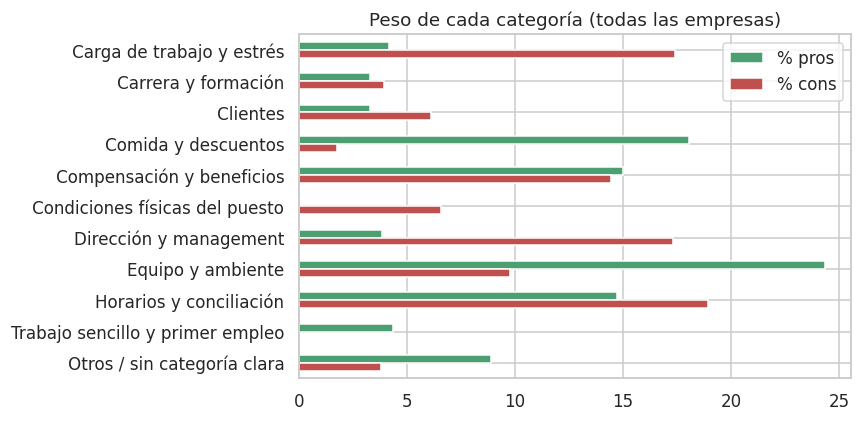

In [ ]:
# Aplicamos las categorías a cada reseña (NaN si el texto no tenía contenido)
# "Sin contenido útil" también pasa a NaN: así NO cuenta en ningún denominador. Si no, una empresa con más
# "no cons" (típicamente la mejor valorada) vería diluidos sus porcentajes en todas las categorías.
def asignar(df_sub, topics, tab, col):
    mapa = dict(zip(tab.topic, tab['categoría'])); mapa[-1] = OTROS
    cat = pd.Series(topics, index=df_sub.index).map(mapa)
    print(f'{col}: excluidas por "sin contenido útil": {(cat == SIN_UTIL).sum()} de {len(cat)}')
    df[col] = cat.where(cat != SIN_UTIL).reindex(df.index)

asignar(pros_df, top_pros, tab_pros, 'cat_pros')
asignar(cons_df, top_cons, tab_cons, 'cat_cons')

# Marcamos qué reseñas eran outliers antes de reasignar (se usan en el análisis de robustez de la sección 4)
for col, d_, orig in [('outlier_pros', pros_df, top_pros_orig), ('outlier_cons', cons_df, top_cons_orig)]:
    df[col] = pd.Series(np.array(orig) == -1, index=d_.index).reindex(df.index).fillna(False).astype(bool)

CATS = sorted((set(df.cat_pros.dropna()) | set(df.cat_cons.dropna())) - {OTROS}) + [OTROS]
CATS_ANALISIS = [c for c in CATS if c != OTROS]   # "Otros" no se interpreta en negocio

# Cuántos pros y cons caen en cada categoría (%)
dist = pd.DataFrame({'% pros': df.cat_pros.value_counts(normalize=True) * 100,
                     '% cons': df.cat_cons.value_counts(normalize=True) * 100}).reindex(CATS).fillna(0)
display(dist.round(1))
dist.plot.barh(figsize=(8, 4), color=['#4c9f70', '#c0504d']); plt.title('Peso de cada categoría (todas las empresas)'); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

In [ ]:
def revisar(col_texto, col_cat, n=3):
    for cat, g in df.dropna(subset=[col_cat]).groupby(col_cat):
        print(f'\n=== {cat} ({len(g)}) ===')
        for t in g[col_texto].sample(min(n, len(g)), random_state=SEED):
            print('  -', textwrap.shorten(t, 170))

print('############ PROS ############'); revisar('pros', 'cat_pros')
print('\n############ CONS ############'); revisar('cons', 'cat_cons')

############ PROS ############

=== Carga de trabajo y estrés (200) ===
  - Easy, simple, fun, friendly, quick.
  - Fast-paced is an understatement!! I enjoy working here and the challenges that I face to become better each day. You will always want to level up and it’s fun to [...]
  - Fun work environment. Fast paced.

=== Carrera y formación (158) ===
  - Dont do it. They don't train properly
  - They train employees well when they are willing to learn
  - Helpful in training process, sharing a common goal

=== Clientes (159) ===
  - some of them are nice and sometimes they try to get you what you want and they usually account for availability
  - Polite Organize Fast paste Clean Dollars per hour
  - Communication with team members and customers

=== Comida y descuentos (870) ===
  - Free food, discounts on food
  - good people, free food, benefits, "good" pay (for a fast food job)
  - Great Deals Good Food Nice People

=== Compensación y beneficios (723) ===
  - Food, Flexibility, 

---
## 4. Comparación con peers

Para cada empresa calculo el % de reseñas (con contenido) cuyos pros caen en cada categoría, y lo mismo con los cons. Como cada empresa suma 100 %, los porcentajes son **relativos**: si una empresa tiene pocas quejas de salario, el peso de "salario" en sus cons baja pero sube el del resto aunque nada haya empeorado. Por eso uso el **balance neto**:

> **balance neto** = % de reseñas que destacan la categoría en pros − % que la mencionan en cons
> **gap** = balance neto de In-N-Out − media del balance neto de los peers (cada peer pesa igual)

Gap positivo = fortaleza relativa; gap negativo = debilidad relativa. Para no sobreinterpretar diferencias pequeñas, calculo un **intervalo de confianza al 95 % por bootstrap** (remuestreando reseñas dentro de cada empresa): solo considero robusta una diferencia cuyo intervalo no incluye el 0.

In [ ]:
def pct_por_categoria(d, col):
    base = d[d[col].notna()]
    t = pd.crosstab(base['firm'], base[col], normalize='index') * 100
    return t.reindex(index=FIRMS, columns=CATS, fill_value=0)

pct_pros = pct_por_categoria(df, 'cat_pros')
pct_cons = pct_por_categoria(df, 'cat_cons')
neto = pct_pros - pct_cons

def vs_peers(t):
    out = pd.DataFrame({TARGET: t.loc[TARGET], 'Media peers': t.loc[PEERS].mean()})
    out['Gap'] = out[TARGET] - out['Media peers']
    return out

comparacion = pd.concat({'PROS (%)': vs_peers(pct_pros), 'CONS (%)': vs_peers(pct_cons), 'BALANCE NETO (pp)': vs_peers(neto)}, axis=1)
display(comparacion.loc[CATS_ANALISIS].round(1))

PROS (%)                   \
                                 In-N-Out-Burger Media peers  Gap   
Carga de trabajo y estrés                    5.2         3.9  1.3   
Carrera y formación                          4.0         3.1  0.9   
Clientes                                     2.1         3.6 -1.5   
Comida y descuentos                         13.0        19.4 -6.5   
Compensación y beneficios                   20.4        13.6  6.8   
Condiciones físicas del puesto               0.0         0.0  0.0   
Dirección y management                       4.0         3.8  0.2   
Equipo y ambiente                           19.7        25.5 -5.9   
Horarios y conciliación                     16.7        14.2  2.4   
Trabajo sencillo y primer empleo             2.0         5.0 -3.0   

                                        CONS (%)                    \
                                 In-N-Out-Burger Media peers   Gap   
Carga de trabajo y estrés                   28.8        14.5  14.3   
Carrera y formación                          3.1         4.2  -1.1   
Clientes                                     4.6         6.5  -1.9   
Comida y descuentos                          0.2         2.2  -1.9   
Compensación y beneficios                    4.1        17.0 -13.0   
Condiciones físicas del puesto               6.5         6.6  -0.1   
Dirección y management                      16.4        17.5  -1.1   
Equipo y ambiente                            7.5        10.3  -2.8   
Horarios y conciliación                     25.9        17.2   8.7   
Trabajo sencillo y primer empleo             0.0         0.0   0.0   

                                 BALANCE NETO (pp)                    
                                   In-N-Out-Burger Media peers   Gap  
Carga de trabajo y estrés                    -23.6       -10.6 -13.0  
Carrera y formación                            0.9        -1.1   2.0  
Clientes                                      -2.5        -2.9   0.4  
Comida y descuentos                           12.7        17.2  -4.5  
Compensación y beneficios                     16.3        -3.4  19.7  
Condiciones físicas del puesto                -6.5        -6.6   0.1  
Dirección y management                       -12.4       -13.8   1.4  
Equipo y ambiente                             12.2        15.2  -3.0  
Horarios y conciliación                       -9.2        -2.9  -6.2  
Trabajo sencillo y primer empleo               2.0         5.0  -3.0

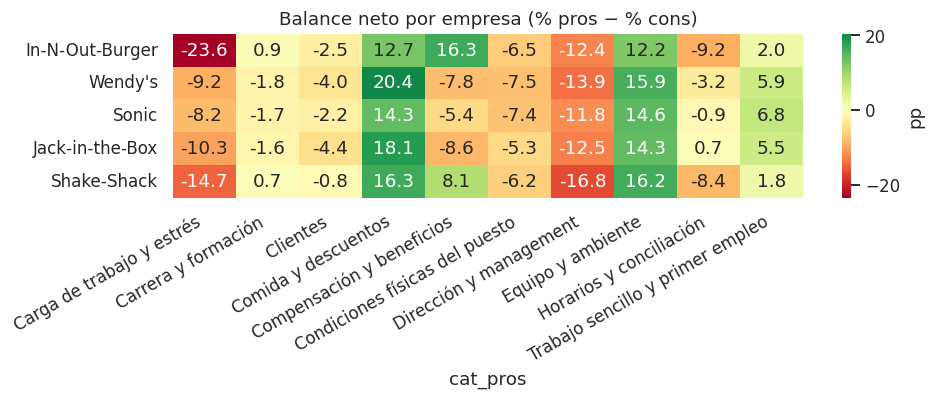

In [ ]:
# Heatmap del balance neto por empresa: verde = la categoría se cita más como fortaleza que como queja
plt.figure(figsize=(9, 3.8))
sns.heatmap(neto[CATS_ANALISIS], annot=True, fmt='.1f', cmap='RdYlGn', center=0, cbar_kws={'label': 'pp'})
plt.title('Balance neto por empresa (% pros − % cons)'); plt.ylabel(''); plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

,gap,ic_inf,ic_sup,robusto
cat_pros,,,,
Carga de trabajo y estrés,-13.0,-16.2,-9.6,True
Horarios y conciliación,-6.2,-9.9,-2.6,True
Comida y descuentos,-4.5,-7.4,-2.0,True
Equipo y ambiente,-3.0,-6.5,0.7,False
Trabajo sencillo y primer empleo,-3.0,-4.0,-2.1,True
Condiciones físicas del puesto,0.1,-1.7,1.6,False
Clientes,0.4,-1.6,2.3,False
Dirección y management,1.4,-1.9,4.4,False
Carrera y formación,2.0,0.3,3.8,True


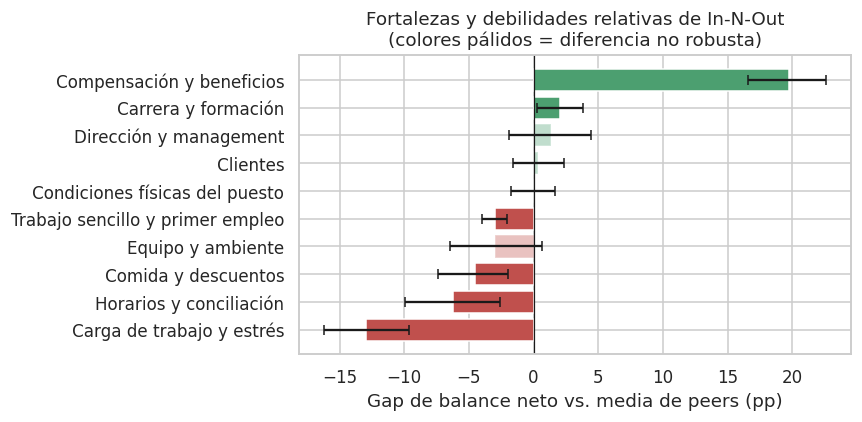

In [ ]:
# Gap de balance neto (target vs media peers) con IC 95% por bootstrap
def gap_neto(d):
    n = pct_por_categoria(d, 'cat_pros') - pct_por_categoria(d, 'cat_cons')
    return n.loc[TARGET] - n.loc[PEERS].mean()

N_BOOT = 300
rng = np.random.default_rng(SEED)
boots = []
for _ in range(N_BOOT):
    b = df.groupby('firm', group_keys=False).sample(frac=1, replace=True, random_state=int(rng.integers(1e9))).reset_index(drop=True)   # índice único (el remuestreo duplica filas)
    boots.append(gap_neto(b))
boots = pd.DataFrame(boots)

gap = gap_neto(df)
ic = boots.quantile([0.025, 0.975]).T
ic.columns = ['ic_inf', 'ic_sup']
gap_tab = pd.concat([gap.rename('gap'), ic], axis=1).loc[CATS_ANALISIS]
gap_tab['robusto'] = (gap_tab.ic_inf > 0) | (gap_tab.ic_sup < 0)    # el IC no incluye el 0
display(gap_tab.sort_values('gap').round(1))

g = gap_tab.sort_values('gap')
fig, ax = plt.subplots(figsize=(8, 4))
err = np.vstack([g.gap - g.ic_inf, g.ic_sup - g.gap])
barras = ax.barh(g.index, g.gap, xerr=err, color=np.where(g.gap >= 0, '#4c9f70', '#c0504d'), capsize=3)
for b, rob in zip(barras, g.robusto): b.set_alpha(1 if rob else 0.35)   # pálido = diferencia no robusta
ax.axvline(0, color='k', lw=0.8); ax.set_xlabel('Gap de balance neto vs. media de peers (pp)')
ax.set_title('Fortalezas y debilidades relativas de In-N-Out\n(colores pálidos = diferencia no robusta)'); plt.tight_layout(); plt.show()

### Análisis de robustez: ¿cambian las conclusiones si quito las reseñas reasignadas?

Las reseñas que BERTopic no supo agrupar al principio (≈ 28 %) se reasignaron por similitud, y parte de esas asignaciones es débil. Repito el gap usando **solo las reseñas que el modelo agrupó por sí mismo**. Si una categoría mantiene el mismo signo en ambos análisis, la conclusión no depende de esa decisión técnica.

In [ ]:
df_rob = df.copy()
df_rob.loc[df_rob['outlier_pros'], 'cat_pros'] = np.nan
df_rob.loc[df_rob['outlier_cons'], 'cat_cons'] = np.nan
gap_rob = gap_neto(df_rob)

robustez = pd.DataFrame({'gap (todas)': gap, 'gap (sin reasignadas)': gap_rob}).loc[CATS_ANALISIS]
robustez['mismo signo'] = np.sign(robustez.iloc[:, 0]) == np.sign(robustez.iloc[:, 1])
display(robustez.round(1))
print(f"Categorías cuya conclusión se mantiene: {robustez['mismo signo'].sum()} de {len(robustez)}")

,gap (todas),gap (sin reasignadas),mismo signo
cat_pros,,,
Carga de trabajo y estrés,-13.0,-12.8,True
Carrera y formación,2.0,2.6,True
Clientes,0.4,-1.0,False
Comida y descuentos,-4.5,-3.5,True
Compensación y beneficios,19.7,14.8,True
Condiciones físicas del puesto,0.1,0.1,True
Dirección y management,1.4,1.3,True
Equipo y ambiente,-3.0,-2.3,True
Horarios y conciliación,-6.2,-5.6,True


Categorías cuya conclusión se mantiene: 9 de 10


### ¿Las quejas de una categoría se reflejan en el rating y la recomendación?

Si una categoría es de verdad un problema, las reseñas que se quejan de ella deberían puntuar peor. Como In-N-Out puntúa más alto que los peers en general, comparo cada reseña con **la media de su propia empresa** (`rating_rel`): así no se mezcla el efecto empresa con el efecto categoría.

% que no recomienda en toda la muestra: 24.1%


,n,rating_rel,pct_no_recomienda
cat_cons,,,
Carga de trabajo y estrés,785.0,0.32,14.52
Carrera y formación,178.0,-0.22,28.65
Clientes,275.0,0.17,23.64
Comida y descuentos,80.0,0.13,30.00
Compensación y beneficios,651.0,-0.27,33.33
Condiciones físicas del puesto,297.0,0.31,14.48
Dirección y management,780.0,-0.62,37.95
Equipo y ambiente,440.0,-0.23,29.09
Horarios y conciliación,853.0,0.06,21.10


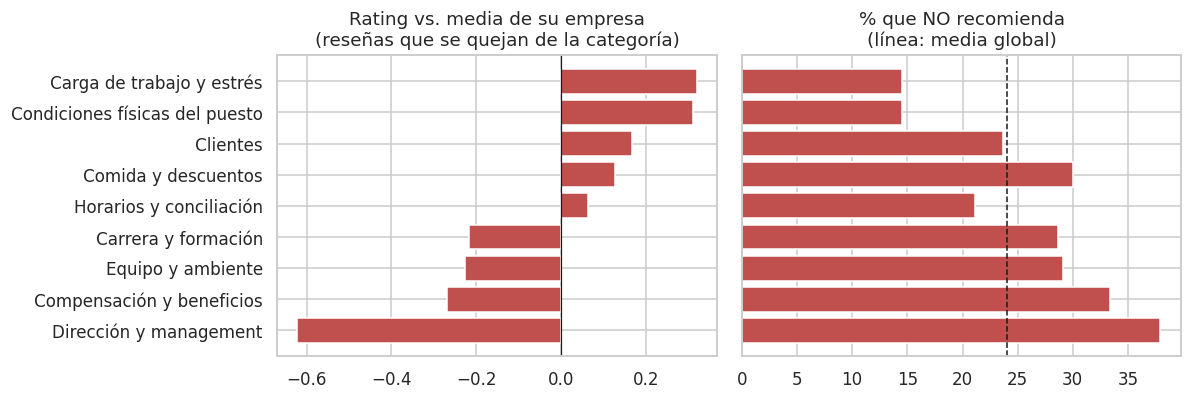

In [ ]:
df['rating_rel'] = df['overall_rating'] - df.groupby('firm')['overall_rating'].transform('mean')
base_no = (df['recomienda'] == 'No').mean() * 100

contraste = (df.dropna(subset=['cat_cons']).groupby('cat_cons')
             .agg(n=('firm', 'size'),
                  rating_rel=('rating_rel', 'mean'),
                  pct_no_recomienda=('recomienda', lambda s: (s == 'No').mean() * 100))
             .reindex(CATS))
print(f'% que no recomienda en toda la muestra: {base_no:.1f}%')
display(contraste.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
c = contraste.loc[CATS_ANALISIS].sort_values('rating_rel')
ax[0].barh(c.index, c.rating_rel, color='#c0504d'); ax[0].axvline(0, color='k', lw=0.8)
ax[0].set_title('Rating vs. media de su empresa\n(reseñas que se quejan de la categoría)')
ax[1].barh(c.index, c.pct_no_recomienda, color='#c0504d'); ax[1].axvline(base_no, color='k', ls='--', lw=1)
ax[1].set_title('% que NO recomienda\n(línea: media global)'); ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()

**Compensación es el gran diferenciador de In-N-Out.** Sus empleados casi no se quejan del salario, y es la queja que más cuesta cuando aparece (−0,27 de rating, 33 % no recomienda).

**Carga y horarios pesan mucho en los cons, pero no se reflejan en el rating.** Son quejas “descriptivas” (“gets busy”), no de insatisfacción. La matriz de priorización los pone arriba por construcción, y el contraste con el rating dice que no son lo urgente.

**Dirección es el problema que sí cuesta puntos.** No estás peor que el mercado, pero es donde más se pierde, y entre los antiguos pesa más que entre los actuales: 18,7 % vs 13,7 %. Con palabras clave, sobre unos 1.300 empleados por grupo, es 22,7 % vs 17,8 %, así que esa diferencia es sólida.

---
## 5. Empleados actuales vs. antiguos

Los cons de quienes ya se han ido son, en la práctica, **motivos de salida**: el input más directo para un plan de retención. Los antiguos puntúan más bajo en todas las empresas (sesgo de selección), así que la comparación útil es la de **temas**, no la de sentimiento.

Aviso: al dividir la muestra por situación, los grupos son más pequeños; se muestra el `n` y se interpretan con prudencia solo las diferencias grandes.

n cons con contenido (In-N-Out): {'Antiguo': 487, 'Actual': 422}


situacion,Actual,Antiguo,Dif. (antiguo − actual)
cat_cons,,,
Carga de trabajo y estrés,31.8,26.3,-5.5
Carrera y formación,2.1,3.9,1.8
Clientes,5.0,4.3,-0.7
Comida y descuentos,0.0,0.4,0.4
Compensación y beneficios,5.5,2.9,-2.6
Condiciones físicas del puesto,5.5,7.4,1.9
Dirección y management,13.7,18.7,4.9
Equipo y ambiente,5.5,9.2,3.8
Horarios y conciliación,27.7,24.2,-3.5


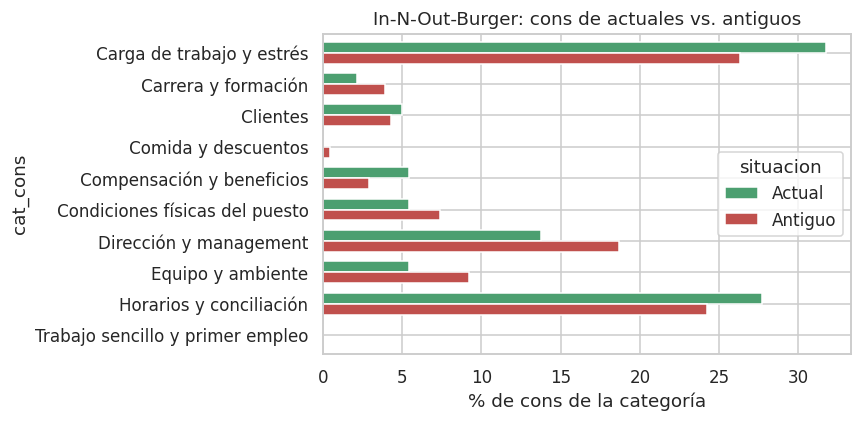

In [ ]:
def pct_cat(d, col, by):
    b = d.dropna(subset=[col])
    return (pd.crosstab(b[by], b[col], normalize='index') * 100).reindex(columns=CATS, fill_value=0)

d_t = df[(df.firm == TARGET) & (df.situacion != 'Desconocido')]
print('n cons con contenido (In-N-Out):', d_t.dropna(subset=['cat_cons']).situacion.value_counts().to_dict())

t5 = pct_cat(d_t, 'cat_cons', 'situacion').T
t5['Dif. (antiguo − actual)'] = t5['Antiguo'] - t5['Actual']
display(t5.loc[CATS_ANALISIS].round(1))

fig, ax = plt.subplots(figsize=(8, 4))
t5.loc[CATS_ANALISIS, ['Actual', 'Antiguo']].plot.barh(ax=ax, color=['#4c9f70', '#c0504d'], width=0.7)
ax.set_xlabel('% de cons de la categoría'); ax.set_title(f'{TARGET}: cons de actuales vs. antiguos'); ax.invert_yaxis(); plt.tight_layout(); plt.show()

### Motivos de salida: los cons de los antiguos de In-N-Out frente a los de los peers

n cons con contenido (antiguos): {'In-N-Out-Burger': 487, "Wendy's": 579, 'Sonic': 582, 'Jack-in-the-Box': 563, 'Shake-Shack': 530}


,In-N-Out-Burger,Media peers,Gap
cat_cons,,,
Carga de trabajo y estrés,26.3,14.1,12.2
Carrera y formación,3.9,3.9,-0.0
Clientes,4.3,6.2,-1.9
Comida y descuentos,0.4,2.1,-1.7
Compensación y beneficios,2.9,16.6,-13.7
Condiciones físicas del puesto,7.4,6.9,0.5
Dirección y management,18.7,19.8,-1.1
Equipo y ambiente,9.2,9.2,-0.0
Horarios y conciliación,24.2,17.2,7.0


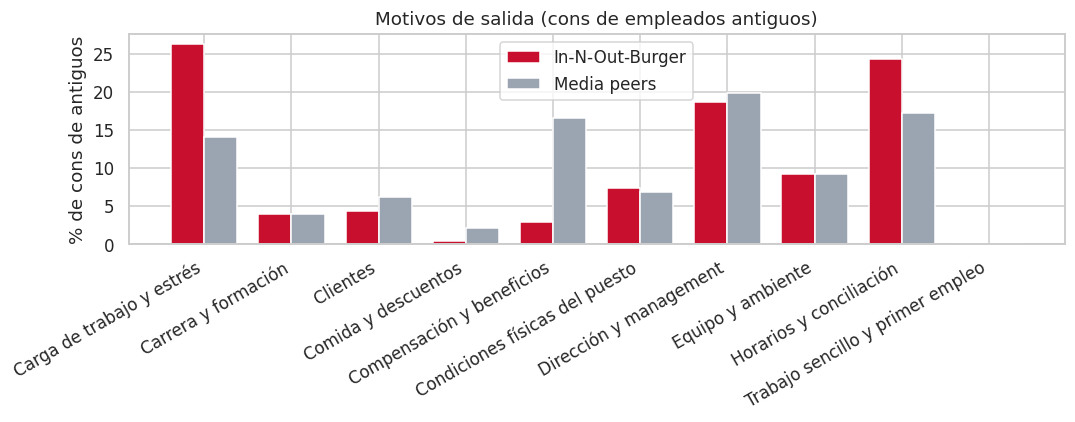

In [ ]:
ant = df[df.situacion == 'Antiguo']
print('n cons con contenido (antiguos):', ant.dropna(subset=['cat_cons']).firm.value_counts().reindex(FIRMS).to_dict())

pct_ant = pct_cat(ant, 'cat_cons', 'firm').reindex(FIRMS)
salida = vs_peers(pct_ant).loc[CATS_ANALISIS]
display(salida.round(1))

x = np.arange(len(CATS_ANALISIS)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - w/2, salida[TARGET], w, color=PALETA[TARGET], label=TARGET)
ax.bar(x + w/2, salida['Media peers'], w, color='#9aa5b1', label='Media peers')
ax.set_xticks(x); ax.set_xticklabels(CATS_ANALISIS, rotation=30, ha='right'); ax.set_ylabel('% de cons de antiguos')
ax.set_title('Motivos de salida (cons de empleados antiguos)'); ax.legend(); plt.tight_layout(); plt.show()

**Motivos de salida frente a los peers:** los antiguos de In-N-Out citan menos el pago (2,9 % vs 16,6 %) y más carga (26,3 % vs 14,1 %) y horarios (24,2 % vs 17,2 %). Aun así siguen puntuando 4,20 de media, así que se van más por el ritmo del puesto que por desencanto.

---
## 6. Matriz de priorización y recomendaciones

Cruzo dos cosas para cada categoría:
- **Peso** en los cons de In-N-Out (¿cuánto se menciona?).
- **Desventaja** frente a los peers = −gap de balance neto (positivo = estamos peor que el mercado).

Un problema solo es prioritario si es **frecuente y además estamos peor que el mercado**. Esa es la esquina superior derecha. Las categorías con desventaja ≤ 0 no son prioridad aunque pesen mucho: es "lo que se queja todo el mundo".

,peso_cons_%,desventaja_pp,robusto,prioridad
Carga de trabajo y estrés,28.8,13.0,True,374.0
Horarios y conciliación,25.9,6.2,True,161.3
Equipo y ambiente,7.5,3.0,False,22.6
Comida y descuentos,0.2,4.5,True,1.0
Carrera y formación,3.1,-2.0,True,0.0
Clientes,4.6,-0.4,False,0.0
Condiciones físicas del puesto,6.5,-0.1,False,0.0
Compensación y beneficios,4.1,-19.7,True,0.0
Dirección y management,16.4,-1.4,False,0.0
Trabajo sencillo y primer empleo,0.0,3.0,True,0.0


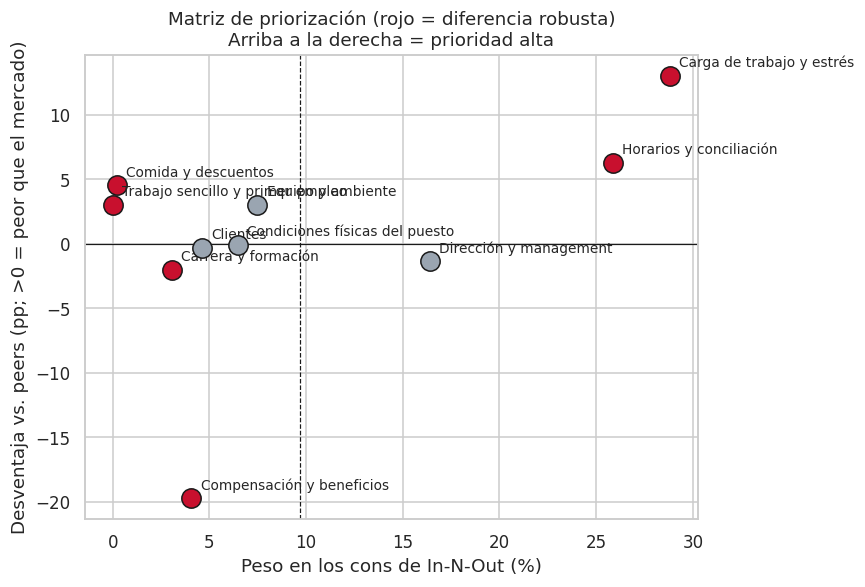

,ventaja neta (pp),ic_inf,ic_sup,robusto
cat_pros,,,,
Compensación y beneficios,19.7,16.6,22.6,True
Carrera y formación,2.0,0.3,3.8,True
Dirección y management,1.4,-1.9,4.4,False
Clientes,0.4,-1.6,2.3,False
Condiciones físicas del puesto,0.1,-1.7,1.6,False


In [ ]:
mat = pd.DataFrame({
    'peso_cons_%': pct_cons.loc[TARGET, CATS_ANALISIS],
    'desventaja_pp': -gap_tab['gap'],
    'robusto': gap_tab['robusto'],
}).loc[CATS_ANALISIS]
mat['prioridad'] = mat['peso_cons_%'] * mat['desventaja_pp'].clip(lower=0)
display(mat.sort_values('prioridad', ascending=False).round(1))

fig, ax = plt.subplots(figsize=(8, 5.5))
for cat, r in mat.iterrows():
    ax.scatter(r['peso_cons_%'], r['desventaja_pp'], s=160, color=PALETA[TARGET] if r['robusto'] else '#9aa5b1', edgecolor='k', zorder=3)
    ax.annotate(cat, (r['peso_cons_%'], r['desventaja_pp']), xytext=(6, 6), textcoords='offset points', fontsize=9)
ax.axhline(0, color='k', lw=0.8); ax.axvline(mat['peso_cons_%'].mean(), color='k', ls='--', lw=0.8)
ax.set_xlabel('Peso en los cons de In-N-Out (%)'); ax.set_ylabel('Desventaja vs. peers (pp; >0 = peor que el mercado)')
ax.set_title('Matriz de priorización (rojo = diferencia robusta)\nArriba a la derecha = prioridad alta')
plt.tight_layout(); plt.show()

# Fortalezas: categorías con mayor ventaja neta frente a peers (útiles para atracción de talento)
display(gap_tab[gap_tab.gap > 0].sort_values('gap', ascending=False).round(1).rename(columns={'gap': 'ventaja neta (pp)'}))

### Recomendaciones

1) Retención: formar y evaluar a los mandos intermedios (feedback, trato, favoritismo). Es la categoría que más baja el rating, crece entre quienes se van y, como los peers tampoco la resuelven, mejorarla sería una ventaja competitiva.

2) Atracción: poner el salario y los beneficios en el centro del employer branding, porque es la ventaja más fuerte y robusta. Hay que vigilarlo, ya que perderla sería lo más costoso.

3) Retención de perfil flexible: reducir la fricción de ritmo y horarios (turnos más predecibles y con más antelación, refuerzo en horas punta, opciones de jornada parcial) y mantener contacto con quienes se van (programa de alumni), dado que su valoración sigue siendo alta.

---
## 7. Conclusiones, limitaciones y próximos pasos

### Hallazgos del EDA
- **In-N-Out es un empleador claramente mejor valorado que sus peers:** rating 4,29 vs. 3,14–3,62; solo 7,8 % no recomienda (22–32 % en los peers).
- **Ex-empleados poco desencantados:** brecha actual–antiguo de 0,19 puntos, la menor del grupo; buena base para un programa de alumni / recontratación.
- **Reputación estable** en toda la ventana (4,22–4,34), también durante la pandemia.

### Hallazgos del NLP

- **Control de calidad del sentimiento:** El modelo clasifica como positivos el 97,4 % de los *pros* de In-N-Out y como negativos el 72,9 % de sus *cons* con contenido. En las empresas competidoras, los *pros* positivos se sitúan entre el 84,2 % y el 89,8 %, mientras que los *cons* negativos alcanzan entre el 85,3 % y el 87,9 %. La diferencia en los *cons* de In-N-Out aconseja interpretar el sentimiento con prudencia: algunas quejas son moderadas, contienen matices positivos o mezclan varias ideas, y el modelo binario puede no identificarlas correctamente. Además, se detectan textos positivos incluidos en el campo de *cons*. Por tanto, el sentimiento resulta útil como control de calidad, pero no es suficiente para identificar ni priorizar los problemas laborales.

- **Fortalezas relativas (gap neto positivo y robusto):** La principal ventaja competitiva de In-N-Out es la **compensación y los beneficios**, con un gap de balance neto de +19,7 puntos porcentuales frente a la media de los competidores (IC del 95 %: +16,6 a +22,6). Los empleados mencionan más esta categoría como fortaleza y mucho menos como queja: solo el 4,1 % de los *cons* de In-N-Out la menciona, frente al 17,0 % de los competidores. También destaca **carrera y formación**, con un gap de +2,0 puntos (IC del 95 %: +0,3 a +3,8), aunque su ventaja es mucho menor. En cambio, las diferencias en dirección y management, clientes y condiciones físicas no son estadísticamente robustas según los intervalos calculados.

- **Debilidades relativas (gap neto negativo y robusto):** Las principales desventajas son **carga de trabajo y estrés** (−13,0 puntos; IC del 95 %: −16,2 a −9,6), **horarios y conciliación** (−6,2 puntos; IC del 95 %: −9,9 a −2,6), **comida y descuentos** (−4,5 puntos; IC del 95 %: −7,4 a −2,0) y **trabajo sencillo y primer empleo** (−3,0 puntos; IC del 95 %: −4,0 a −2,1). La carga de trabajo y los horarios son los hallazgos más relevantes desde una perspectiva operativa, ya que aparecen con frecuencia en los *cons* y su balance neto es peor que el de los competidores. No obstante, la comprobación frente al rating indica que mencionar estas categorías no se asocia necesariamente con una peor valoración relativa. Por ello, deben interpretarse como áreas de fricción y mejora, no automáticamente como las causas más graves de insatisfacción. El análisis de robustez mantiene el signo de 9 de las 10 categorías al excluir las reseñas reasignadas por similitud, lo que respalda la estabilidad general de los resultados.

- **Motivos de salida (cons de antiguos empleados):** Los antiguos empleados de In-N-Out mencionan con mayor frecuencia la **carga de trabajo y el estrés** (26,3 %, frente al 14,1 % de la media de los competidores) y los **horarios y la conciliación** (24,2 %, frente al 17,2 %). La compensación aparece mucho menos como motivo de queja (2,9 %, frente al 16,6 % de los competidores). Además, las quejas sobre dirección y management aumentan del 13,7 % entre los empleados actuales al 18,7 % entre los antiguos. Aunque estas diferencias descriptivas no demuestran causalidad, apuntan a que el ritmo de trabajo, la organización de los turnos y la experiencia con los mandos son aspectos relevantes para investigar en las decisiones de salida. Los antiguos empleados siguen registrando una valoración media de 4,20, por lo que abandonar la empresa no equivale necesariamente a tener una experiencia laboral negativa en su conjunto.

- **Palancas de retención y atracción:** Para la retención, conviene priorizar la mejora de la gestión de los mandos intermedios —especialmente el feedback, el trato y la percepción de favoritismo—, así como reducir la fricción asociada a la carga de trabajo y los horarios mediante turnos más previsibles, planificación anticipada y refuerzos en horas punta. Para la atracción, la compensación y los beneficios deben ocupar un lugar central en la propuesta de valor al empleado, dado que constituyen la ventaja relativa más clara y robusta de In-N-Out. Por último, mantener el contacto con los antiguos empleados y explorar programas de alumni o recontratación puede ser una oportunidad, siempre que se tengan en cuenta sus motivos de salida y sus preferencias laborales.

### Limitaciones del análisis
- **Representatividad de Glassdoor:** reseñas voluntarias, con tendencia a extremos (muy contentos o muy descontentos) y a antiguos empleados; no representan a toda la plantilla.
- **Mezcla de roles y países:** el dataset combina personal de restaurante, encargados y oficinas corporativas, y no distingue franquicias de restaurantes propios (In-N-Out es 100 % propia; muchos peers operan con franquiciados), lo que puede explicar parte de las diferencias.
- **Comparabilidad de peers:** Shake Shack es *fast casual* premium; el resto es comida rápida clásica.
- **Precisión de los topics:** BERTopic asigna **un único topic** a cada reseña aunque mencione varios temas, y la agrupación en categorías mezcla criterio automático y manual.
- **Muestra y significatividad:** modelos entrenados con 1.000 reseñas por empresa; los grupos pequeños (p. ej. antiguos por categoría) tienen intervalos amplios.
- **Cons con elogios:** algunos cons son frases positivas (*"None! Great place to work"*) que el filtro de textos vacíos no siempre detecta; se revisan a mano en la sección 3.
- **Ventana temporal:** 2023 solo llega a abril.

### Próximos pasos propuestos
- Ampliar la muestra (hasta las 2.000+ reseñas por empresa) y probar `nr_topics` / otros `min_cluster_size` para validar la estabilidad de las categorías.
- Segmentar por **rol** (equipo de tienda vs. encargados) cuando haya datos, y por antigüedad.
- Seguimiento trimestral de las categorías prioritarias para evaluar el efecto de las acciones.